In [69]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.special import spherical_jn
from scipy.integrate import quad
from mpmath import quadosc
from mpmath import inf, log10
import camb
from mcfit import P2xi

In [24]:
import sys
sys.path.append('../src/')
from polybessel import PolyBessel

In [89]:
pars = camb.set_params(H0=67.5, ombh2=0.022, omch2=0.122, ns=0.965)
pars.set_matter_power(redshifts=[0.6], kmax=20.0)

# Linear spectra
#pars.NonLinear = model.NonLinear_none
results = camb.get_results(pars)
kh, z, pk = results.get_matter_power_spectrum(minkh=1e-4, maxkh=10, npoints=256)

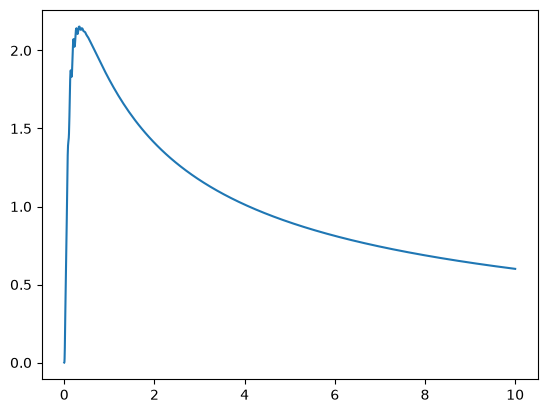

In [90]:
plt.plot(kh, kh**2*pk[0]/2/np.pi**2)

In [91]:
r, xi = P2xi(kh)(pk[0])

In [25]:
PB = PolyBessel(spherical_bessel=True)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [71]:
rpb = np.linspace(1, 250, 128)
f = lambda y: 10**(CubicSpline(np.log10(kh), np.log10(kh**2*pk[0]/2/np.pi**2))(np.log10(y)))
xipb = PB.compute_many_single_bessel(f, [0], rpb, kh.min(), kh.max())[0]

/Users/alexlague/Documents/act/sfb/repo/polybessel/notebooks/../src/interpolation.py:329: UserWarning: cheb_fit_adaptive: f not resolved with 512 nodes on [0.0001, 10]
  warnings.warn("cheb_fit_adaptive: f not resolved with %d nodes on [%g, %g]" % (n, a, b))


In [73]:
xiquad = np.array([quad(lambda y: f(y) * spherical_jn(0, ri*y), kh.min(), kh.max(), limit=10000) for ri in rpb])

(0.0, 250.0)

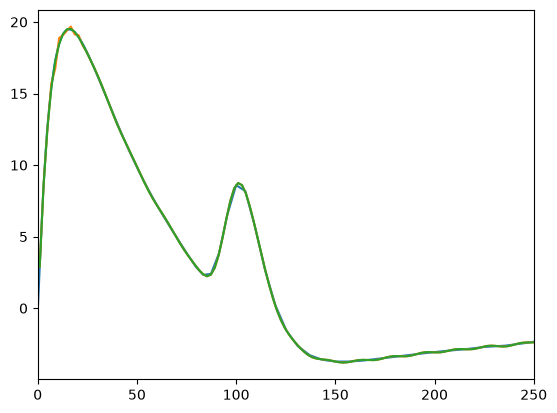

In [92]:
plt.plot(r, r**2*xi)
plt.plot(rpb, rpb**2*xipb)
plt.plot(rpb, rpb**2*xiquad[:,0])
plt.xlim(0, 250)

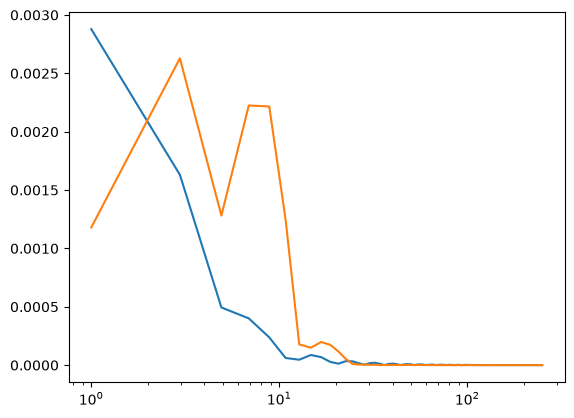

In [93]:
plt.plot(rpb, np.abs(CubicSpline(r, xi)(rpb)-xiquad[:,0])/xiquad[:,0].max())
plt.plot(rpb, np.abs(xipb-xiquad[:,0])/xiquad[:,0].max())
plt.xscale('log')

In [95]:
%timeit r, xi = P2xi(kh)(pk[0])

133 μs ± 2.67 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [83]:
%timeit PB.compute_many_single_bessel(f, [0], rpb, kh.min(), kh.max())[0]

111 ms ± 577 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [94]:
%timeit f(np.logspace(-1, 1, 256))

79.6 μs ± 3.1 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
